# Indexed Line Chart (rebased to 100)

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Divides each series by its value at a common start date and multiplies by 100, so all series start at 100 and show relative growth. It is the honest replacement for a dual-axis chart when series have very different units or scales.

## When to use

- Compare growth of series with very different magnitudes (a small-cap vs. an index)
- You are tempted to use a second y-axis. Index instead, so there is one honest scale
- Show performance since an event (rebased at the event date)

## Avoid when

- Absolute levels matter more than relative change
- The base period is unusual (spike or trough), which distorts every later value

## Alternatives

- Two separate charts stacked vertically
- Small multiples

## Design tips

- State the base date in the axis label or title ('Jan 2020 = 100')
- Draw a reference line at 100
- Consider a log scale when growth is multiplicative and large

## Example

Users (thousands) and sessions (millions) of a product: different scales, compared by growth.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(14)
dates = pd.date_range("2023-01", periods=30, freq="MS")
t = np.arange(30)
df = pd.DataFrame({
    "Users (k)": 12 + 0.9 * t + rng.normal(0, 0.5, 30),
    "Sessions (M)": 0.35 + 0.004 * t ** 1.6 + rng.normal(0, 0.01, 30),
    "Revenue ($M)": 2.1 + 0.03 * t + rng.normal(0, 0.05, 30),
}, index=dates)
indexed = df / df.iloc[0] * 100
labels = dict(y="Index (Jan 2023 = 100)",
              title="Growth since Jan 2023: one honest axis instead of three")
indexed.head()

,Users (k),Sessions (M),Revenue ($M)
2023-01-01,100.000000,100.000000,100.000000
2023-02-01,100.506189,98.862540,101.346412
2023-03-01,105.389601,98.403243,108.014534
2023-04-01,107.205800,104.085097,107.990838
2023-05-01,124.908356,105.261729,108.185034


### Plot

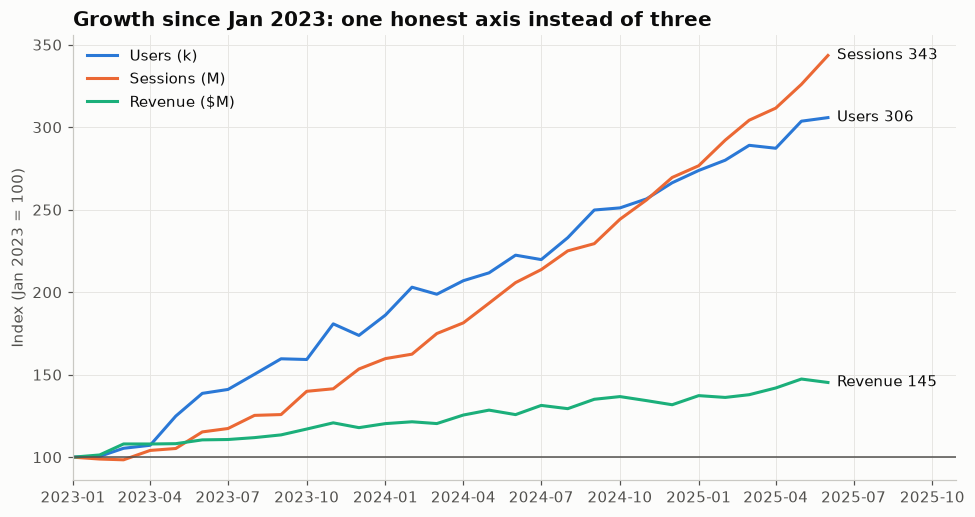

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
span = indexed.index[-1] - indexed.index[0]
for i, col in enumerate(indexed.columns):
    ax.plot(indexed.index, indexed[col], color=PALETTE[i], label=col)
    ax.text(indexed.index[-1] + span * 0.012, indexed[col].iloc[-1],
            f"{col.split(' (')[0]} {indexed[col].iloc[-1]:.0f}", va="center", fontsize=9.5)
ax.axhline(100, color="#52514e", linewidth=1)
ax.set_xlim(indexed.index[0], indexed.index[-1] + span * 0.17)
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## How to read it

Every series starts at 100. A value of 250 means 2.5× its January 2023 level, whatever its original units. Sessions grew fastest even though their raw numbers are on a completely different scale.

## Try it with real data

**Source:** plotly.express.data.gapminder() — Gapminder life expectancy, GDP and population 1952–2007, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
gm = px.data.gapminder().query("country == 'India'")
df = pd.DataFrame({"Population (M)": gm["pop"].values / 1e6,
                   "GDP per capita ($)": gm["gdpPercap"].values,
                   "Life expectancy (yrs)": gm["lifeExp"].values},
                  index=pd.to_datetime(gm["year"].astype(str)))
indexed = df / df.iloc[0] * 100
labels = dict(y="Index (1952 = 100)", title="India since 1952: three measures on one honest axis")
indexed.head()

,Population (M),GDP per capita ($),Life expectancy (yrs)
year,,,
1952-01-01,100.000000,100.000000,100.000000
1957-01-01,109.946237,107.958100,107.695395
1962-01-01,122.043011,120.451593,116.675140
1967-01-01,136.021505,128.213415,126.275654
1972-01-01,152.419355,132.469429,135.528323


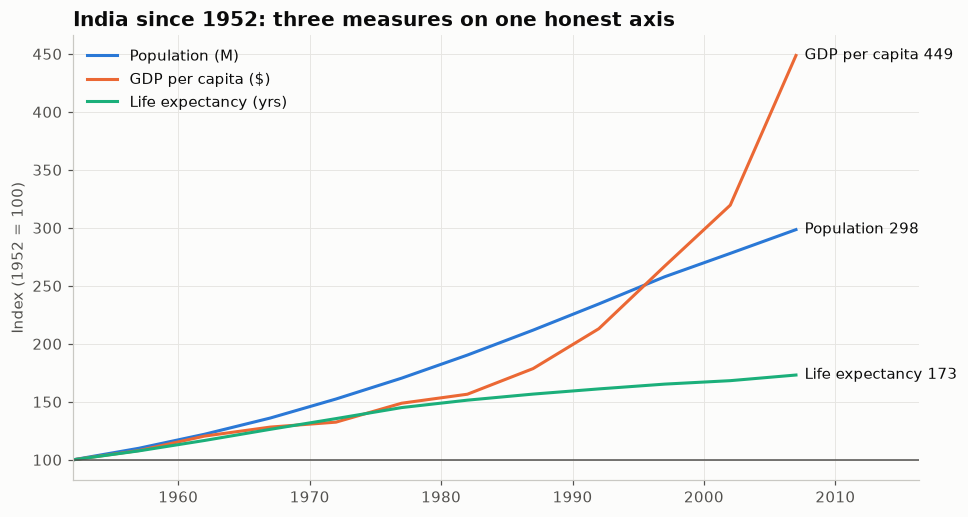

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
span = indexed.index[-1] - indexed.index[0]
for i, col in enumerate(indexed.columns):
    ax.plot(indexed.index, indexed[col], color=PALETTE[i], label=col)
    ax.text(indexed.index[-1] + span * 0.012, indexed[col].iloc[-1],
            f"{col.split(' (')[0]} {indexed[col].iloc[-1]:.0f}", va="center", fontsize=9.5)
ax.axhline(100, color="#52514e", linewidth=1)
ax.set_xlim(indexed.index[0], indexed.index[-1] + span * 0.17)
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

---
Standalone script: [`indexed_line.py`](indexed_line.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)